In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [6]:
# Load the cleaned ATS pairs dataset (from Notebook 01)
df = pd.read_csv('/content/cleaned_resumeJD_pairs.csv')
print(f"Loaded: {df.shape[0] } rows, {df.shape[1]} columns")
print(f"Columns: {df.columns.tolist()}")
print(f"\nLabel distribution:")
print(df['match_label'].value_counts())
df.head(3)

Loaded: 280 rows, 7 columns
Columns: ['resume_text', 'job_description', 'match_label', 'match_score', 'match_label_lower', 'resume_len', 'jd_len']

Label distribution:
match_label
medium    110
high       93
low        77
Name: count, dtype: int64


,resume_text,job_description,match_label,match_score,match_label_lower,resume_len,jd_len
0,BI Analyst with 7 years of experience based in...,Fathom is hiring a Financial Analyst (Berlin)....,medium,0.53,medium,75,71
1,Data Scientist with 13 years of experience bas...,Lumen is hiring a Senior UX Designer (Singapor...,low,0.26,low,79,74
2,Software Engineer with 8 years of experience b...,Acme Corp is hiring a Product Manager (Seattle...,low,0.31,low,71,80


In [7]:
print('loading the BERT model...')

model = SentenceTransformer('all-mpnet-base-v2')

print("Model Loaded.")
print(f" Model  : all-mpnet-base-v2")
print(f" parameters:          22.7M")
print(f" Embed dims:   768")
print(f" Max Tokens: {model.max_seq_length}")

loading the BERT model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model Loaded.
 Model  : all-mpnet-base-v2
 parameters:          22.7M
 Embed dims:   768
 Max Tokens: 384


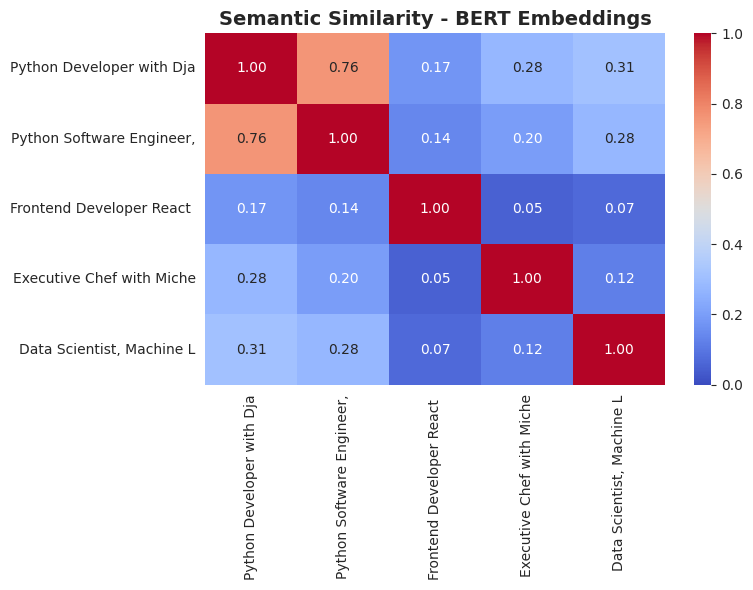

In [10]:
# Part 2: Understanding Embeddings
texts = [
    "Python Developer with Django experience",
    "Python Software Engineer, Django REST APIs",
    "Frontend Developer React and JavaScript",
    "Executive Chef with Michelin experience",
    "Data Scientist, Machine Learning, PyTorch",
]

embeddings = model.encode(texts)
sim_matrix = cosine_similarity(embeddings)

plt.figure(figsize=(8, 6))
sns.heatmap(sim_matrix, annot=True, fmt=".2f", cmap="coolwarm", xticklabels=[t[:25] for t in texts],
            yticklabels=[t[:25] for t in texts], vmin=0, vmax=1)
plt.title("Semantic Similarity - BERT Embeddings", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# Generating resume JD Embeddings
# We embed Both Resume and Job description seperately

print("Generating Resume Embedding...")
resume_embeddings = model.encode(
    df['resume_text'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
)

print("Generating JD Embedding...")
jd_embeddings = model.encode(
    df['job_description'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
)

print(f"\nResume Embedding Shape: {resume_embeddings.shape}")
print(f"JD Embedding Shape: {jd_embeddings.shape}")
print(f"Each Text -> {resume_embeddings.shape[1]}-dimensional vector")

Generating Resume Embedding...


Batches:   0%|          | 0/9 [00:00<?, ?it/s]

Generating JD Embedding...


Batches:   0%|          | 0/9 [00:00<?, ?it/s]


Resume Embedding Shape: (280, 768)
JD Embedding Shape: (280, 768)
Each Text -> 768-dimensional vector


In [13]:
# Compute Cosine Similarity for each pair
# For Each row: Similarity between that resume and its paired JD

pair_similarities = []

for i in range(len(resume_embeddings)):
    similarity = cosine_similarity([resume_embeddings[i]], [jd_embeddings[i]])[0][0]
    pair_similarities.append(similarity)

# Assign to DataFrame and print after the loop finishes
df['bert_similarity'] = pair_similarities

print("Cosine similarity computed for all pairs")
print(df[['match_label', 'match_score', 'bert_similarity']].head(10))

Cosine similarity computed for all pairs
  match_label  match_score  bert_similarity
0      medium         0.53         0.554188
1         low         0.26         0.489453
2         low         0.31         0.471076
3      medium         0.46         0.620440
4        high         0.77         0.660347
5        high         0.92         0.608102
6         low         0.13         0.515025
7      medium         0.45         0.619569
8      medium         0.46         0.562903
9      medium         0.48         0.479238


In [14]:
# Base Model Performance: How Good Is BERT out of the Box?

mae = mean_absolute_error(df['match_score'], df['bert_similarity'])
rmse = np.sqrt(mean_squared_error(df['match_score'], df['bert_similarity']))

print("Base BERT Model Performance (before fine tuning)")
print("=" * 50)
print(f" MAE: {mae:.4f} (lower is better)")
print(f" RMSE: {rmse:.4f} (lower is better)")

Base BERT Model Performance (before fine tuning)
 MAE: 0.1789 (lower is better)
 RMSE: 0.2188 (lower is better)


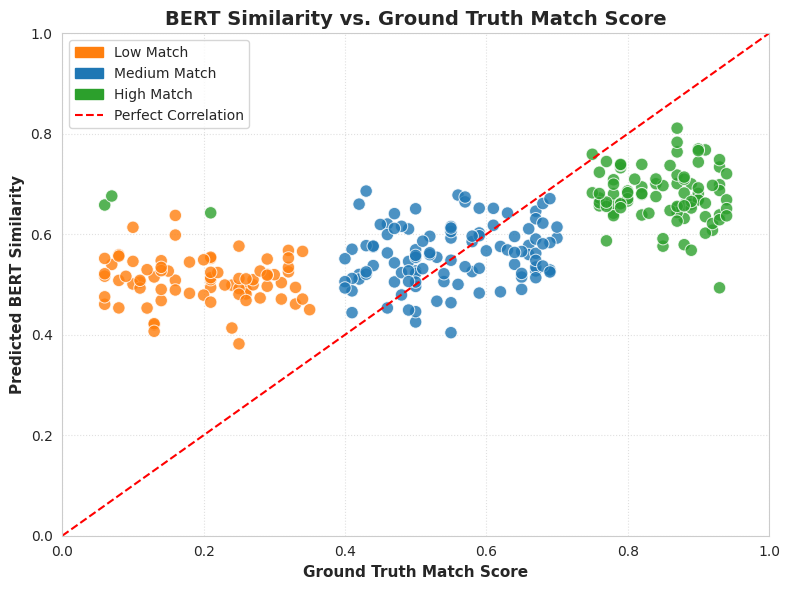

In [16]:
import matplotlib.patches as mpatches

# Define a custom color palette for the labels
colors = {'low': '#ff7f0e', 'medium': '#1f77b4', 'high': '#2ca02c'}

plt.figure(figsize=(8, 6))

# Create the scatter plot using the defined colors
sns.scatterplot(
    data=df,
    x='match_score',
    y='bert_similarity',
    hue='match_label',
    palette=colors,
    alpha=0.8,
    edgecolor='w',
    s=80
)

# Add a diagonal reference line representing perfect correlation
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Perfect Correlation (1:1)')

# Set labels and title
plt.xlabel('Ground Truth Match Score', fontsize=11, fontweight='bold')
plt.ylabel('Predicted BERT Similarity', fontsize=11, fontweight='bold')
plt.title('BERT Similarity vs. Ground Truth Match Score', fontsize=14, fontweight='bold')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, linestyle=':', alpha=0.6)

# Create custom legend handles using matplotlib.patches.Patch
legend_patches = [
    mpatches.Patch(color=colors['low'], label='Low Match'),
    mpatches.Patch(color=colors['medium'], label='Medium Match'),
    mpatches.Patch(color=colors['high'], label='High Match'),
    plt.Line2D([0], [0], color='red', linestyle='--', label='Perfect Correlation')
]

plt.legend(handles=legend_patches, loc='upper left')
plt.tight_layout()
plt.show()

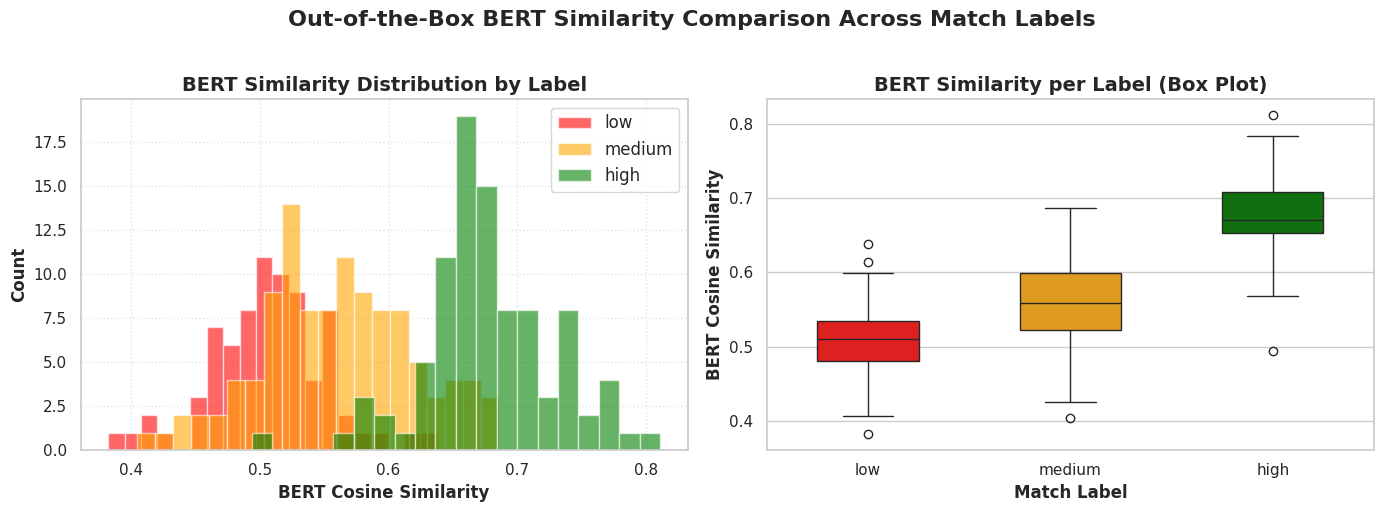

In [23]:
# Set up the plotting style and custom colors
sns.set_theme(style="whitegrid")
colors = {'low': 'red', 'medium': 'orange', 'high': 'green'}
label_order = ['low', 'medium', 'high']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Histogram
for label in label_order:
    subset = df[df['match_label'] == label]['bert_similarity']
    axes[0].hist(subset, bins=20, alpha=0.6, color=colors[label], label=label)

axes[0].set_xlabel('BERT Cosine Similarity', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[0].set_title('BERT Similarity Distribution by Label', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=12)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Right plot: Box Plot grouped in logical order using Seaborn for color consistency
sns.boxplot(
    data=df,
    x='match_label',
    y='bert_similarity',
    order=label_order,
    palette=colors,
    width=0.5,
    ax=axes[1]
)

axes[1].set_xlabel('Match Label', fontsize=12, fontweight='bold')
axes[1].set_ylabel('BERT Cosine Similarity', fontsize=12, fontweight='bold')
axes[1].set_title('BERT Similarity per Label (Box Plot)', fontsize=14, fontweight='bold')

plt.suptitle('Out-of-the-Box BERT Similarity Comparison Across Match Labels', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [25]:
import pickle

with open('reume_embedding.pkl', 'wb') as f:
  pickle.dump({
      'resume_embeddings': resume_embeddings,
      'jd_embeddings': jd_embeddings,
      'match_scores': df['match_score'].tolist(),
      'match_labels': df['match_label'].tolist(),
  }, f)
print("Saved: resume_embedding.pkl")
print(f"Resume Embedding : {resume_embeddings.shape}")
print(f"JD Embedding : {jd_embeddings.shape}")
print()
print("These will Be Loaded For Fine Tuning")

Saved: resume_embedding.pkl
Resume Embedding : (280, 768)
JD Embedding : (280, 768)

These will Be Loaded For Fine Tuning
